# A small in-house model that answers covenant-headroom questions: SFT, then RL with a verifiable reward

**Story.** A lender has to answer, every quarter and for every loan: *is the borrower in compliance, how far can its
earnings fall, and how much more debt can it take before a covenant is breached?* Borrower figures are confidential and
decisions must be auditable, so the system should run in-house. We train an open 7B model (Qwen2.5-Coder-7B + LoRA) to
turn each covenant into an SMT formula over the certificate's line items; the Z3 solver then answers all three questions
exactly. Supervised training on 789 teacher pairs gives a usable formalizer; reinforcement learning with a label-free,
solver-checked reward that also enforces the formula interface lifts it further, above open models 4-5x larger that read
the clause directly. Formulas can be proven correct, and two independent
formulas that Z3 proves equivalent are almost always right: a label-free self-check that decides which covenants run
automatically.

Every number below is computed from raw result files by `src/headroom/paper.py`. Tables are written as booktabs LaTeX
(`results/paper/tables/*.tex`, package: `booktabs`) and shown rendered; figures follow the figures4papers house style
and are saved as PDF and PNG (`results/paper/figures/`). Pre-registration and every later change: `docs/headroom_PLAN.md`.

In [1]:
import sys
from pathlib import Path
SRC = Path.cwd().parent / 'src'
sys.path[:0] = [str(SRC)] + [str(d) for d in sorted(SRC.iterdir()) if d.is_dir() and not d.name.startswith(('_', '.'))]
import paper
from IPython.display import Image, Markdown, display

def show_table(fn):
    latex, markdown = fn()[:2]
    display(Markdown(markdown))
    print(latex)

def show_fig(fn, width=1100):
    display(Image(filename=str(fn()), width=width))

## 0. Overview

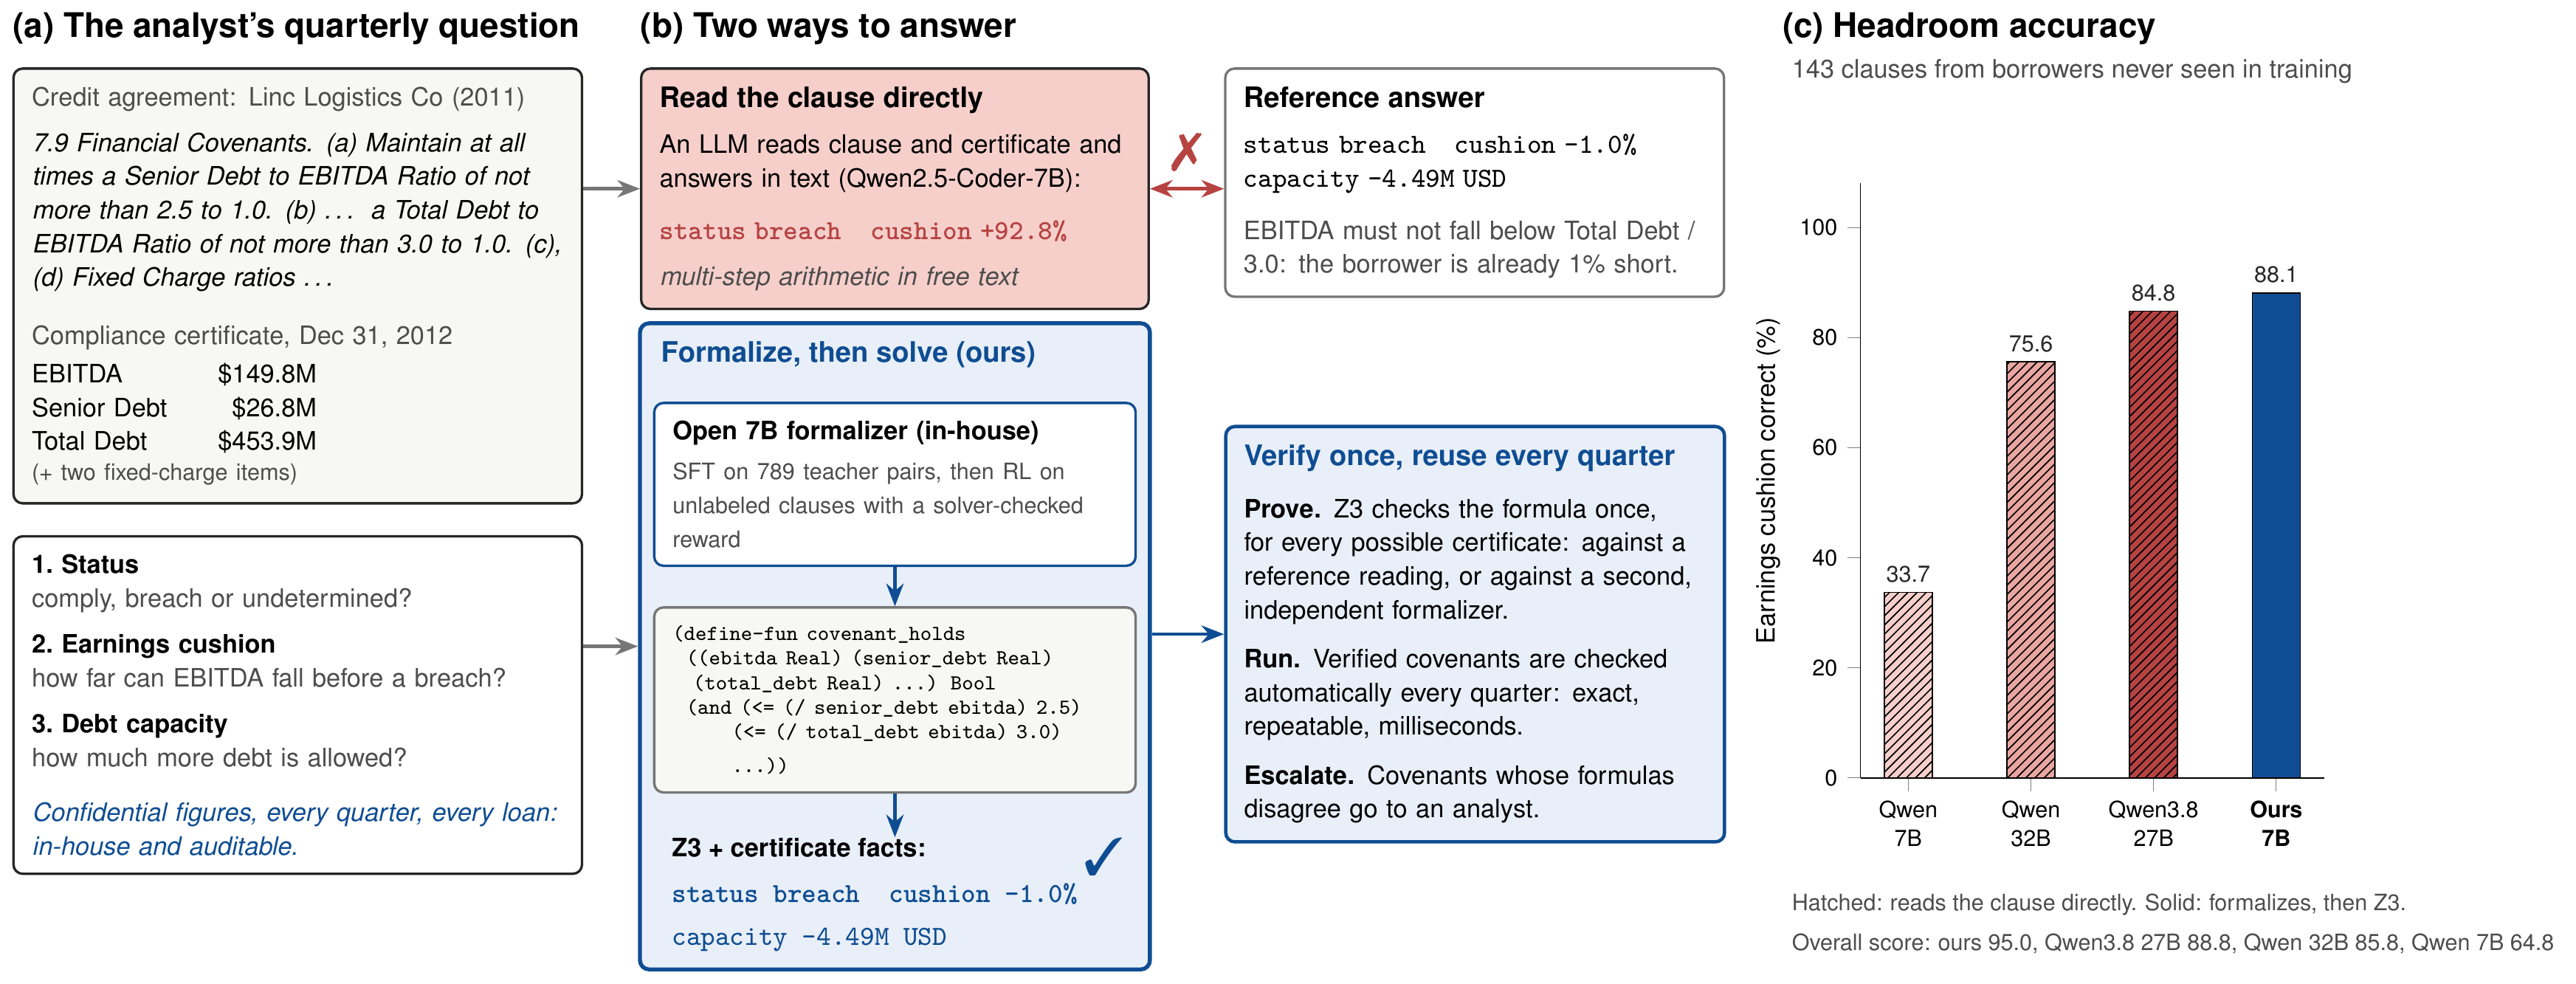

In [2]:
show_fig(paper.fig_overview_tex, 1400)

**Figure 0.** (a) Every quarter, for every loan, an analyst needs a covenant's status, earnings cushion and debt capacity
from the clause and the compliance certificate. (b) A real benchmark case (borrower 1% short of its Total Debt / EBITDA
limit): a 7B model reading the clause directly gets it wrong; our in-house 7B formalizer writes a formula once, and Z3
answers exactly. Formulas are proven once and reused every quarter. (c) Earnings-cushion accuracy on borrowers never seen
in training. The figure is TikZ/pgfplots (`results/paper/figures/fig0_overview.tex`), with every number filled in from
the result files.

## Method

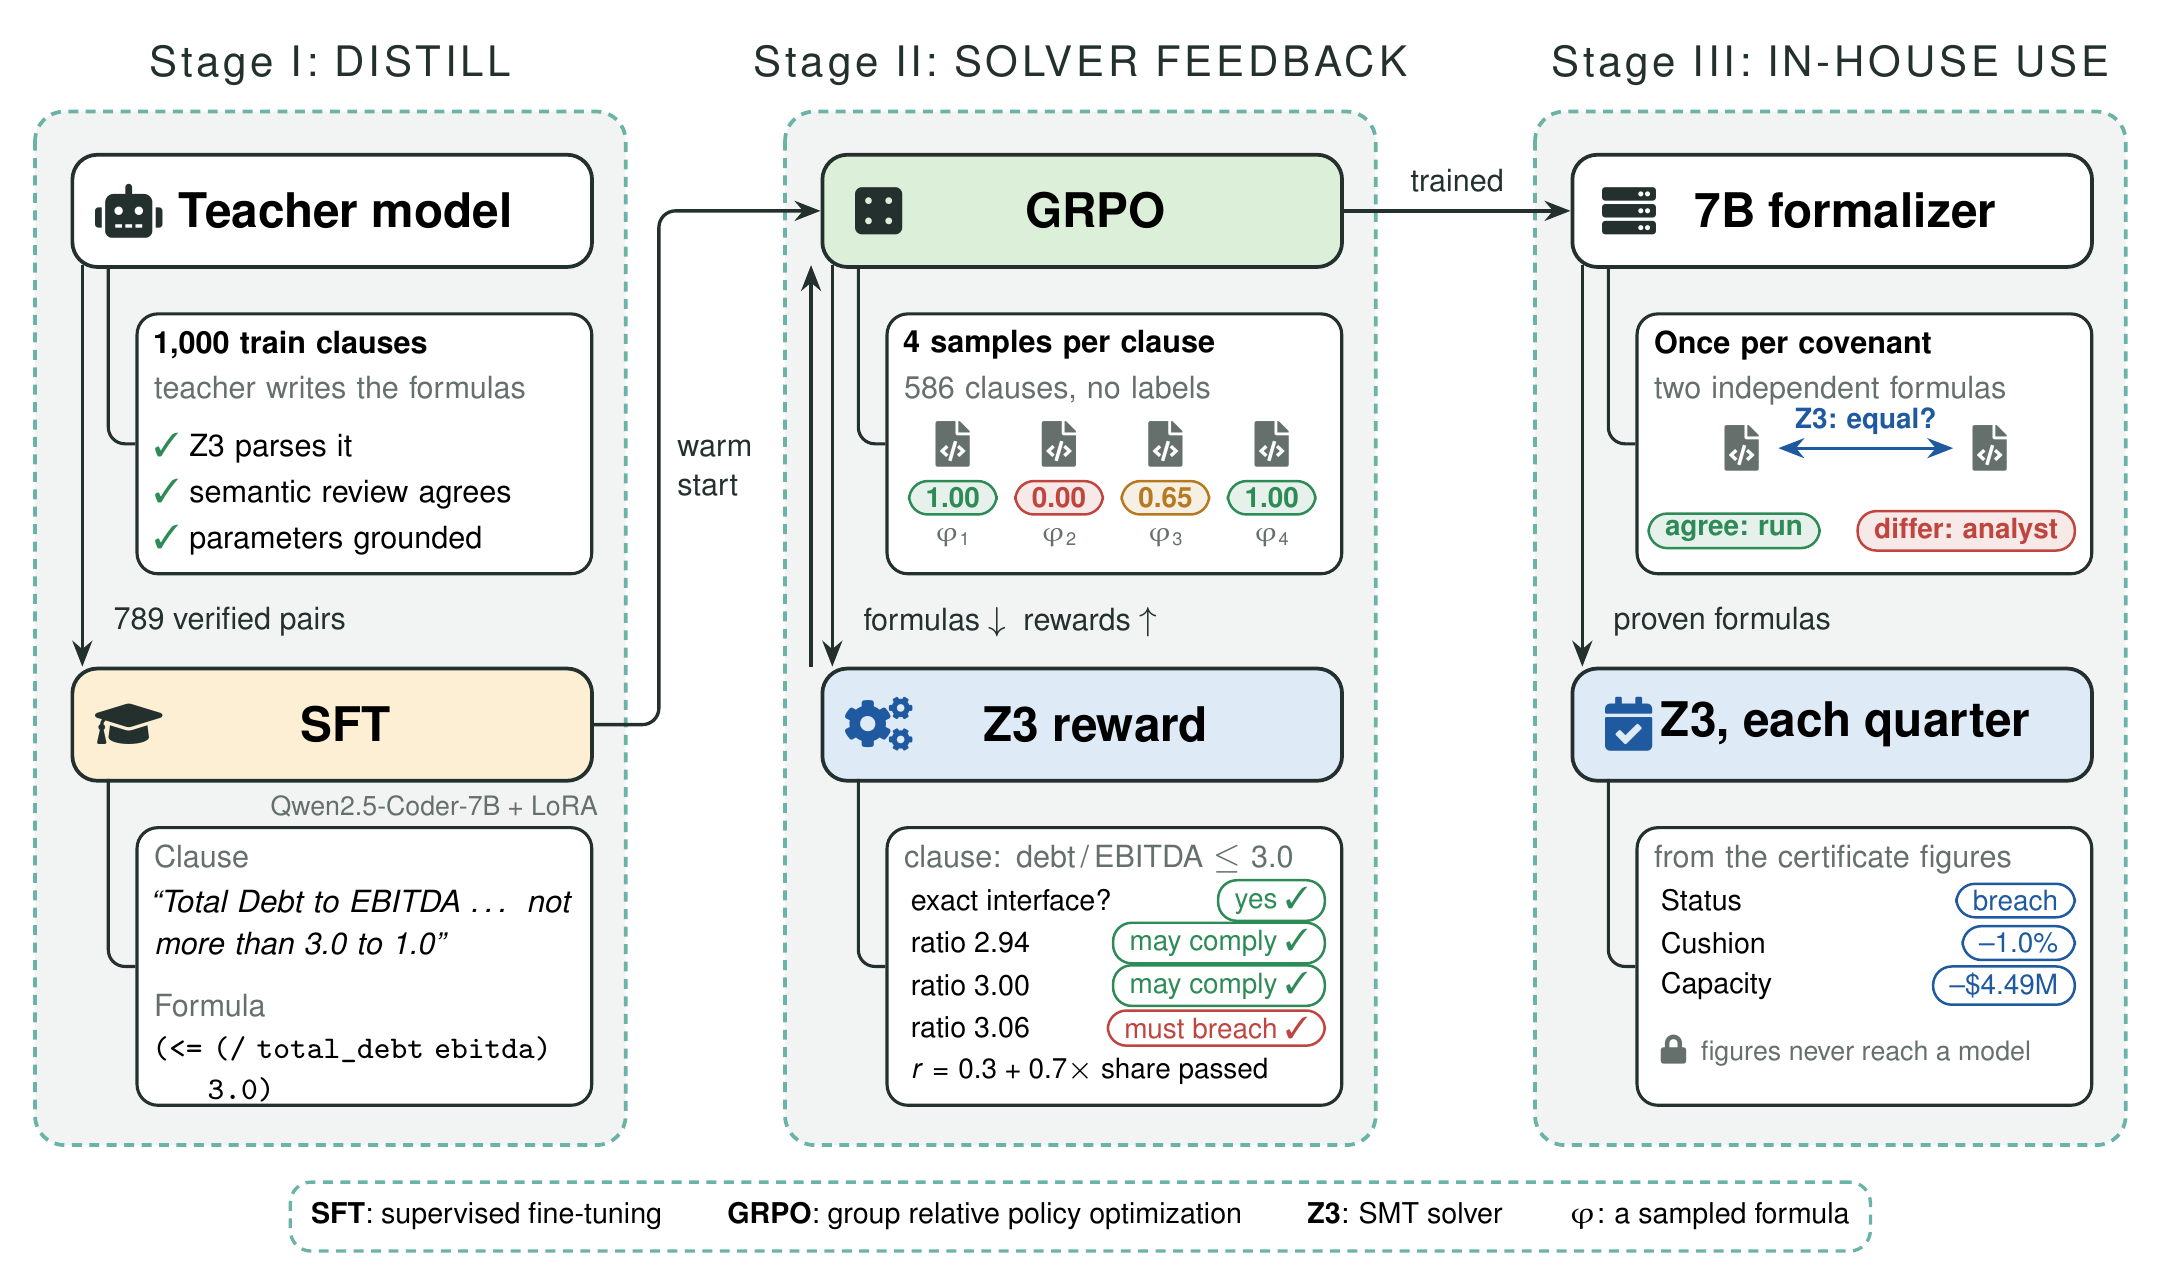

In [3]:
show_fig(paper.fig_method_tex, 1300)

**Figure M.** Stage I: teacher formulas filtered by Z3 and a semantic review train the 7B model with SFT. Stage II: GRPO
on unlabeled clauses; Z3 scores each sampled formula (0 if the parameter interface breaks, else 0.3 + 0.7 x the share of
threshold tests passed). Stage III: in-house, formulas proven equal by two formalizers run every quarter; the rest go to
an analyst.

## 1. The benchmark
Borrower-disjoint clauses, two-reader reference readings, constructed certificates, and a 100% reference validation through the same Z3 code the formalizers use.

In [4]:
show_table(paper.table_benchmark)

| | Item | Count |
|---|---|---|
| Source | Borrower-disjoint test clauses (no borrower appears in training) | 533 |
|  | Excluded: no numeric covenant, dependent or redacted threshold (reader A / B) | 189 |
|  | Excluded: ratio named without its components (status-only) | 113 |
|  | Excluded: the two readers disagree | 62 (of 225 read by both) |
|  | Kept reference readings (both readers agree exactly) | 163 |
| Benchmark | Clauses with cases | 143 |
|  | Agreements / borrowers | 108 / 103 |
|  | Agreement years | 1993--2015 |
|  | Clauses with several limits / with date schedules or conditions | 32 / 27 |
|  | Cases (constructed certificates) | 1,064 |
|  | Status: comply / breach / undetermined | 556 / 370 / 138 |
|  | Cases asking the earnings cushion / the debt capacity | 745 / 718 |
| Validation | Reference answers reproduced by the formula-arm Z3 code | 1,064 / 1,064 |

\begin{table}[t]
\centering
\small
\setlength{\tabcolsep}{5pt}
\caption{The headroom benchmark. Clauses come from agreements whose borrowers never appear in any training data; each kept clause has a reference reading on which two independent readers (Claude and Qwen3.8-27B) agree exactly. Certificates are constructed so that the binding limit sits at a chosen cushion.}
\label{tab:benchmark}
\begin{adjustbox}{max width=\linewidth}
\begin{tabular}{@{}llr@{}}
\toprule
 & \textbf{Item} & \textbf{Count} \\
\midrule
Source & Borrower-disjoint test clauses (no borrower appears in training) & 533 \\
 & Excluded: no numeric covenant, dependent or redacted threshold (reader A / B) & 189 \\
 & Excluded: ratio named without its components (status-only) & 113 \\
 & Excluded: the two readers disagree & 62 (of 225 read by both) \\
 & Kept reference readings (both readers agree exactly) & 163 \\
\midrule
Benchmark & Clauses with cases & 143 \\
 & Agreements / borrowers & 108 / 103 \\
 & Agreement year

## 2. Main result

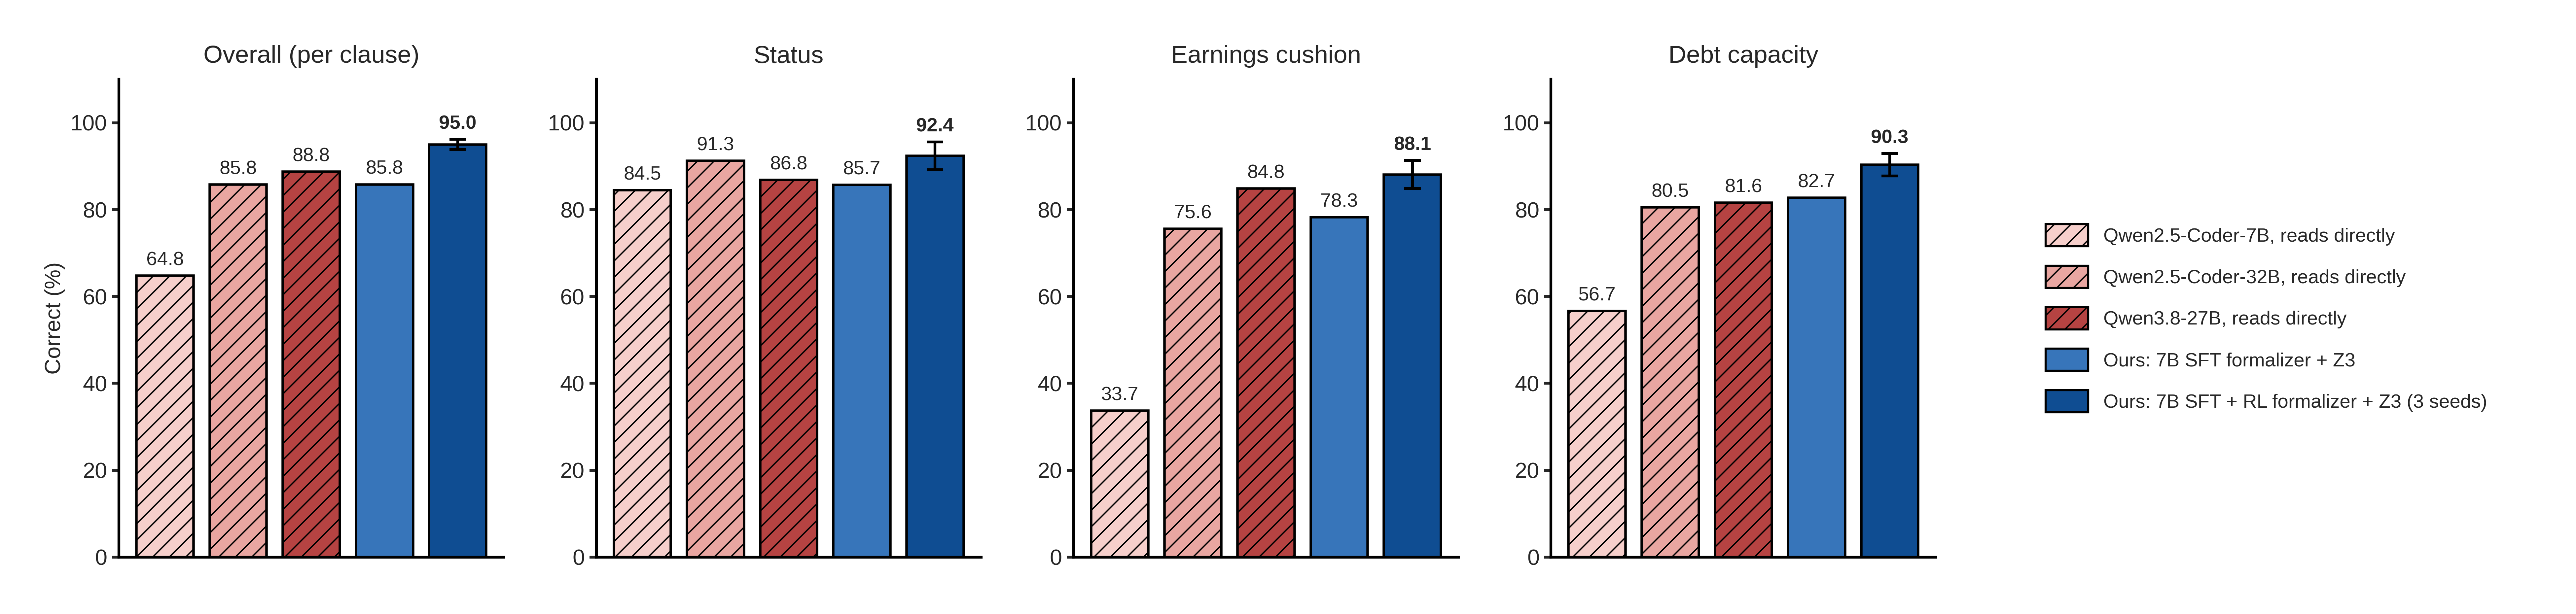

In [5]:
show_fig(paper.fig_main, 1300)

**Figure 1.** Share of questions answered correctly on 1,064 cases (143 clauses). Hatched red: open models that read the
clause and answer directly; blue: our 7B formalizers with Z3. The error bar on SFT + RL is one standard deviation over
three seeds.

In [6]:
show_table(paper.table_main)

| System | Size | Score [95% CI] | Status | Cushion | Capacity | Verified |
|---|---|---|---|---|---|---|
| *Reads the clause directly* | | | | | | |
| Qwen2.5-Coder-7B | 7B | 64.8 [62.0, 67.6] | 84.5 | 33.7 | 56.7 | -- |
| Qwen2.5-Coder-32B | 32B | 85.8 [82.8, 88.6] | 91.3 | 75.6 | 80.5 | -- |
| Qwen3.8-27B | 27B | 88.8 [84.7, 92.4] | 86.8 | 84.8 | 81.6 | -- |
| *Formalizes, then Z3 decides (Qwen2.5-Coder-7B + LoRA)* | | | | | | |
| Prompted, no training | 7B | 53.2 [45.1, 61.1] | 44.5 | 34.2 | 43.9 | 46.9 |
| SFT (789 pairs) | 7B | 85.8 [80.4, 90.8] | 85.7 | 78.3 | 82.7 | 60.8 |
| SFT + RL, v1 (no interface term) | 7B | 58.4 [50.7, 66.1] | 64.3 | 61.1 | 60.9 | 38.5 |
| SFT + RL v2 (ours, 3 seeds) | 7B | 95.0 ± 1.2 [92.2, 97.4] | 92.4 ± 3.2 | 88.1 ± 3.2 | 90.3 ± 2.6 | 70.9 ± 0.4 |

\begin{table*}[t]
\centering
\small
\setlength{\tabcolsep}{6pt}
\caption{Headroom questions on the borrower-disjoint benchmark (143 clauses, 1,064 cases). Score: mean per-clause share of questions answered correctly, with a 95\% clause-bootstrap interval. Status: comply / breach / undetermined; earnings cushion: within 0.5 percentage points; debt capacity: within 0.5\% of the current debt. Verified: formulas proven equivalent to the reference reading by Z3 for all inputs. All models are open-weights and run in-house. \textbf{Bold}: best. RL v2: mean $\pm$ s.d. over three seeds; the other systems are single greedy runs. Direct readers were given 4,096 answer tokens.}
\label{tab:main}
\begin{adjustbox}{max width=\linewidth}
\begin{tabular}{@{}lcccccc@{}}
\toprule
\textbf{System} & \textbf{Size} & \textbf{Score} & \textbf{Status} & \textbf{Cushion} & \textbf{Capacity} & \textbf{Verified} \\
\midrule
\multicolumn{7}{@{}l}{\textit{Reads the clause directly}} \\
\quad Qwen2.5-Coder-7B & 7B &

In [7]:
show_table(paper.table_paired)

| RL v2 minus | Δ (points) | 95% CI | p (Holm) | Per seed |
|---|---|---|---|---|
| SFT (same model before RL) | +9.2 | [+4.6, +14.2] | 0.0004 | +9.2/+10.3/+8.0 |
| Qwen2.5-Coder-7B, reading directly | +30.2 | [+26.9, +33.5] | 0.0004 | +30.3/+31.4/+29.0 |
| Qwen2.5-Coder-32B, reading directly | +9.2 | [+5.8, +12.6] | 0.0004 | +9.3/+10.4/+8.0 |
| Qwen3.8-27B, reading directly | +6.3 | [+2.1, +10.5] | 0.0035 | +6.3/+7.4/+5.1 |
| *Training stages and equal-size comparisons* | | | | |
| SFT minus prompted formalizer | +32.6 | [+24.2, +41.0] | 0.0004 | -- |
| RL v1 minus SFT | -27.4 | [-35.7, -19.1] | 0.0004 | -- |
| SFT formalizer minus 7B reading | +21.0 | [+15.2, +26.5] | 0.0004 | -- |
| Prompted formalizer minus 7B reading | -11.6 | [-19.6, -3.8] | 0.0045 | -- |

\begin{table}[t]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{SFT + RL v2 (three-seed mean) minus each comparator: mean per-clause difference in points, 95\% clause-bootstrap interval, two-sided sign-flip test over the 143 clauses (10,000 permutations), Holm-corrected over the four comparisons. Seeds: the difference for each of the three RL seeds. Lower block: a separate Holm family of four comparisons.}
\label{tab:paired}
\begin{adjustbox}{max width=\linewidth}
\begin{tabular}{@{}lrcrr@{}}
\toprule
\textbf{RL v2 minus} & \textbf{$\Delta$} & \textbf{95\% CI} & \textbf{$p_{\mathrm{Holm}}$} & \textbf{Seeds} \\
\midrule
SFT (same model before RL) & +9.2 & [+4.6, +14.2] & $<$0.001 & {\scriptsize +9.2/+10.3/+8.0} \\
Qwen2.5-Coder-7B, reading directly & +30.2 & [+26.9, +33.5] & $<$0.001 & {\scriptsize +30.3/+31.4/+29.0} \\
Qwen2.5-Coder-32B, reading directly & +9.2 & [+5.8, +12.6] & $<$0.001 & {\scriptsize +9.3/+10.4/+8.0} \\
Qwen3.8-27B, reading directly & +6.3 & [+2.1, +10.5] & 0

**Reading.** RL with the interface-enforcing reward adds about 9 points over SFT on every seed, and the resulting 7B
formalizer beats Qwen3.8-27B (+6.3, p_Holm = 0.004) and Qwen2.5-Coder-32B (+9.2, p_Holm < 0.001) reading the clause
directly. The first RL run, without the interface term, often dropped required parameters and
fell to 58.4; it is reported, not hidden (Table 2).

## 3. Size

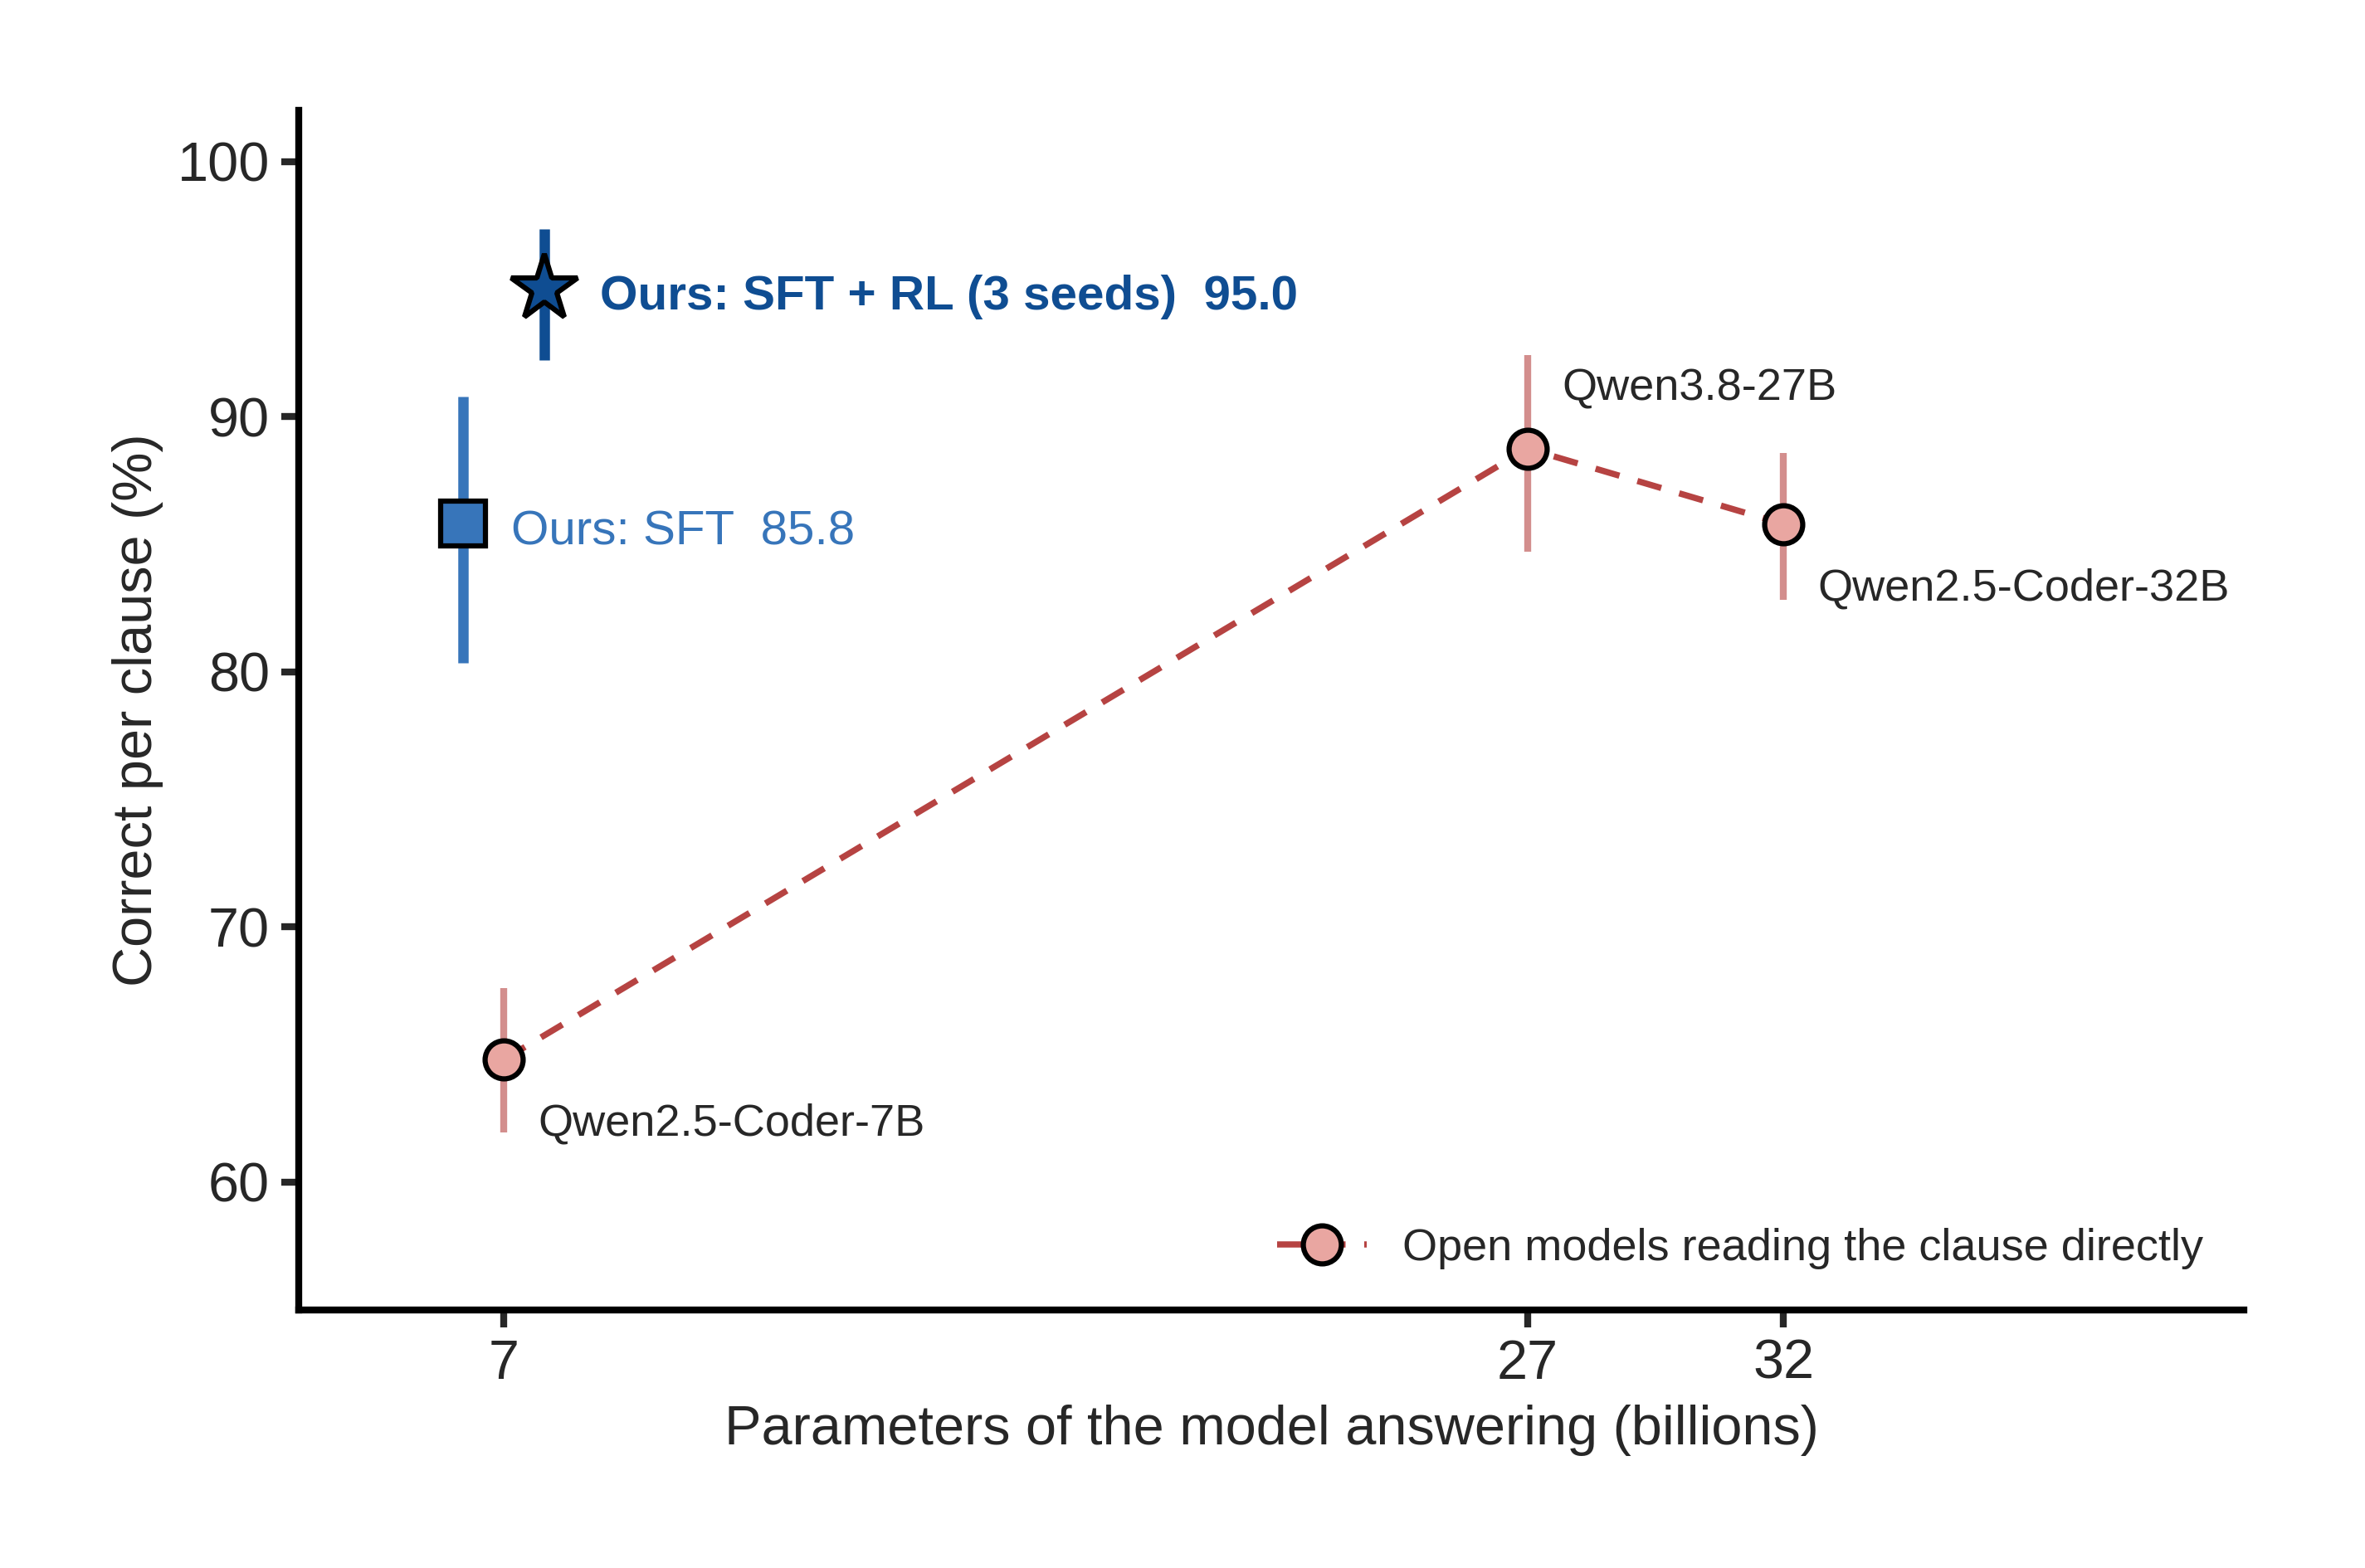

In [8]:
show_fig(paper.fig_size, 800)

**Figure 2.** Per-clause score against the size of the answering model; open readers with 95% clause-bootstrap intervals, and our two 7B formalizers.

## 4. Verification: proofs instead of samples

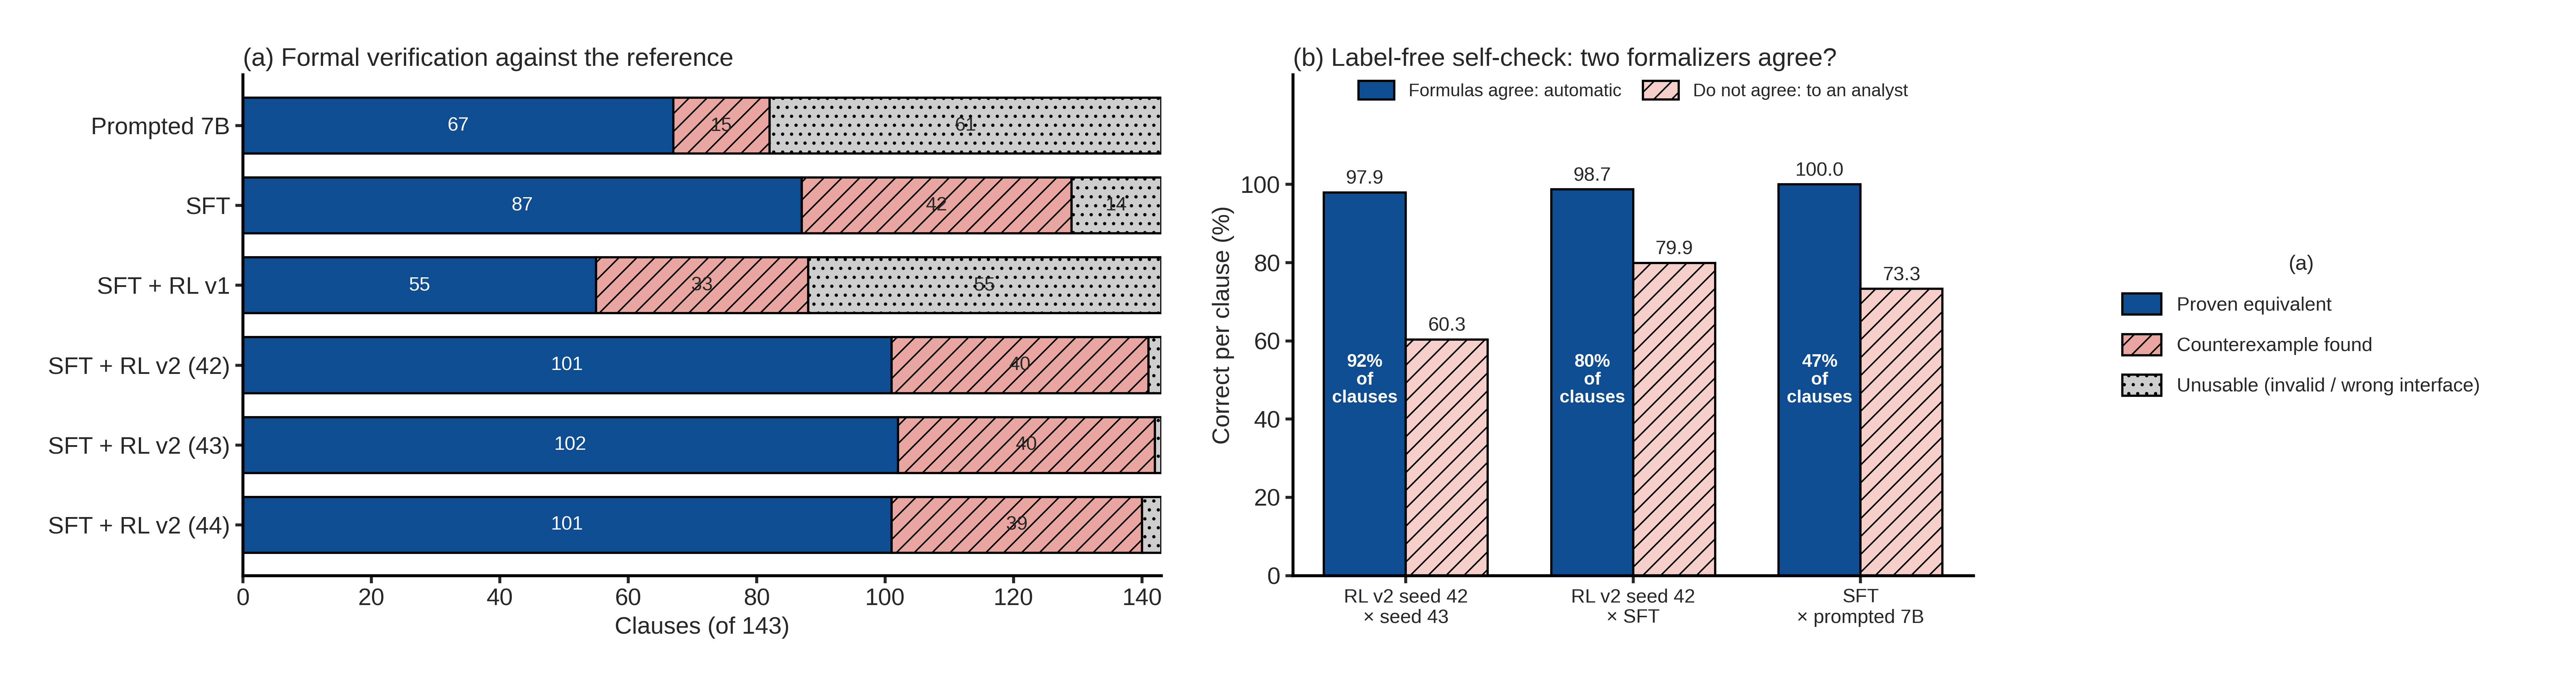

In [9]:
show_fig(paper.fig_verification, 1300)

**Figure 4.** (a) Z3 proves each formula equivalent to the reference reading for every input, finds a counterexample, or
the formula is unusable. (b) Without any reference: two formalizers write formulas for the same clause and Z3 checks
whether they agree for every input. Agreed clauses run automatically; the rest go to an analyst.

In [10]:
show_table(paper.table_verification)

| Formalizer | Equivalent | Different | Unusable | Score, equivalent | Score, not equivalent |
|---|---|---|---|---|---|
| Prompted, no training | 67 | 15 | 61 | 100.0 | 11.9 |
| SFT (789 pairs) | 87 | 42 | 14 | 100.0 | 63.8 |
| SFT + RL v1 | 55 | 33 | 55 | 100.0 | 32.4 |
| SFT + RL v2, seed 42 | 101 | 40 | 2 | 100.0 | 83.1 |
| SFT + RL v2, seed 43 | 102 | 40 | 1 | 100.0 | 86.6 |
| SFT + RL v2, seed 44 | 101 | 39 | 3 | 100.0 | 79.0 |

\begin{table}[t]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{Formal verification of the generated formulas (143 clauses). Equivalent: Z3 proves the formula equal to the reference reading for every input (line items $>0$, positive ratio denominators, any test date in 1990--2030); different: Z3 finds a counterexample; unusable: invalid SMT or wrong parameters. Accuracy: case-level score on the clauses in each group.}
\label{tab:verification}
\begin{adjustbox}{max width=\linewidth}
\begin{tabular}{@{}lrrrcc@{}}
\toprule
 & \multicolumn{3}{c}{\textbf{Clauses}} & \multicolumn{2}{c}{\textbf{Score on clauses}} \\
\cmidrule(lr){2-4}\cmidrule(l){5-6}
\textbf{Formalizer (7B)} & \textbf{Equiv.} & \textbf{Diff.} & \textbf{Unus.} & \textbf{equivalent} & \textbf{not equivalent} \\
\midrule
Prompted, no training & 67 & 15 & 61 & 100.0 & 11.9 \\
SFT (789 pairs) & 87 & 42 & 14 & 100.0 & 63.8 \\
SFT + RL v1 & 55 & 33 & 55 & 100.0 & 32.4 \\
SFT + RL v2, seed 42 & 101 & 40 & 2 & 100.0 & 83.1 \\

In [11]:
show_table(paper.table_selfcheck)

| Pair | Agree (coverage) | Score, agreed | Score, to analyst |
|---|---|---|---|
| RL v2 seed 42 × seed 43 | 132 / 143 (92%) | 97.9 | 60.3 |
| RL v2 seed 42 × SFT | 115 / 143 (80%) | 98.7 | 79.9 |
| SFT × prompted 7B | 67 / 143 (47%) | 100.0 | 73.3 |

\begin{table}[t]
\centering
\small
\setlength{\tabcolsep}{5pt}
\caption{Label-free self-check. Two formalizers write a formula for the same clause and Z3 checks whether the two are equivalent for all inputs; no reference reading is used. Agreed clauses could be checked automatically every quarter; the rest go to an analyst. Score: the first formalizer's case-level score on each group.}
\label{tab:selfcheck}
\begin{tabular}{@{}lccc@{}}
\toprule
\textbf{Pair of formalizers} & \textbf{Agree (coverage)} & \textbf{Score, agreed} & \textbf{Score, to analyst} \\
\midrule
RL v2 seed 42 $\times$ seed 43 & 132 / 143 (92\%) & 97.9 & 60.3 \\
RL v2 seed 42 $\times$ SFT & 115 / 143 (80\%) & 98.7 & 79.9 \\
SFT $\times$ prompted 7B & 67 / 143 (47\%) & 100.0 & 73.3 \\
\bottomrule
\end{tabular}
\end{table}


## 5. Training

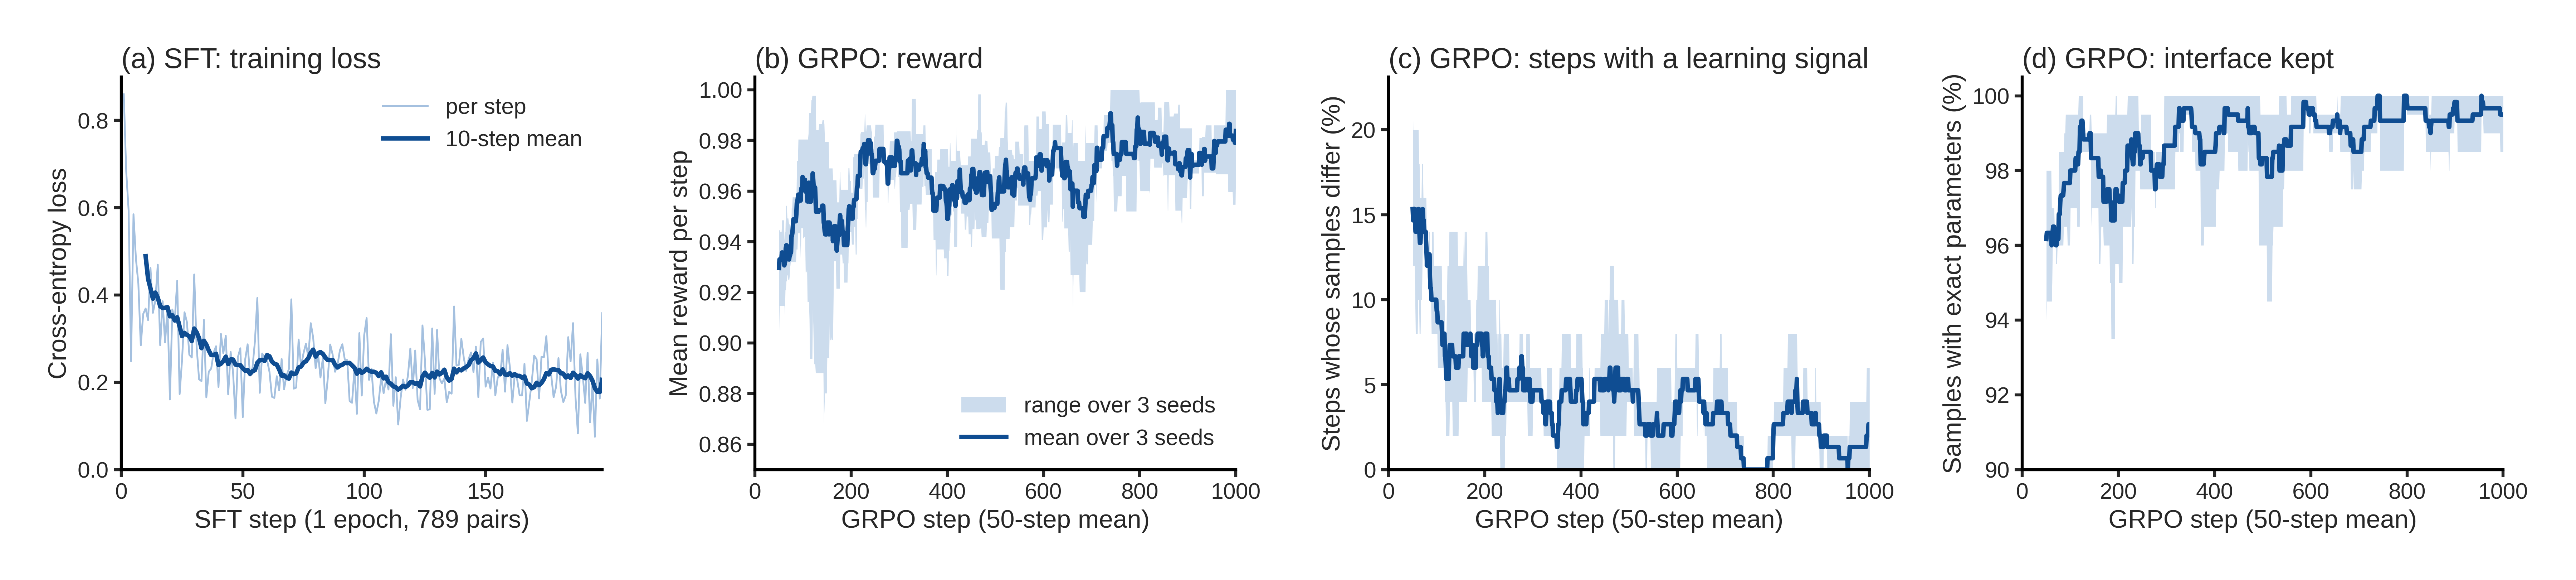

In [12]:
show_fig(paper.fig_training, 1100)

**Figure 3.** Learning curves. (a) SFT loss over one epoch on 789 pairs. (b-d) GRPO, three seeds: (b) reward; (c) share
of steps whose four samples differ in reward, the only steps with a gradient (95.5 ± 0.6% of steps carry none); (d) share
of samples that keep the required parameter interface. A few dozen informative steps move the model by 9 points.

## 6. Where it helps, and where it does not

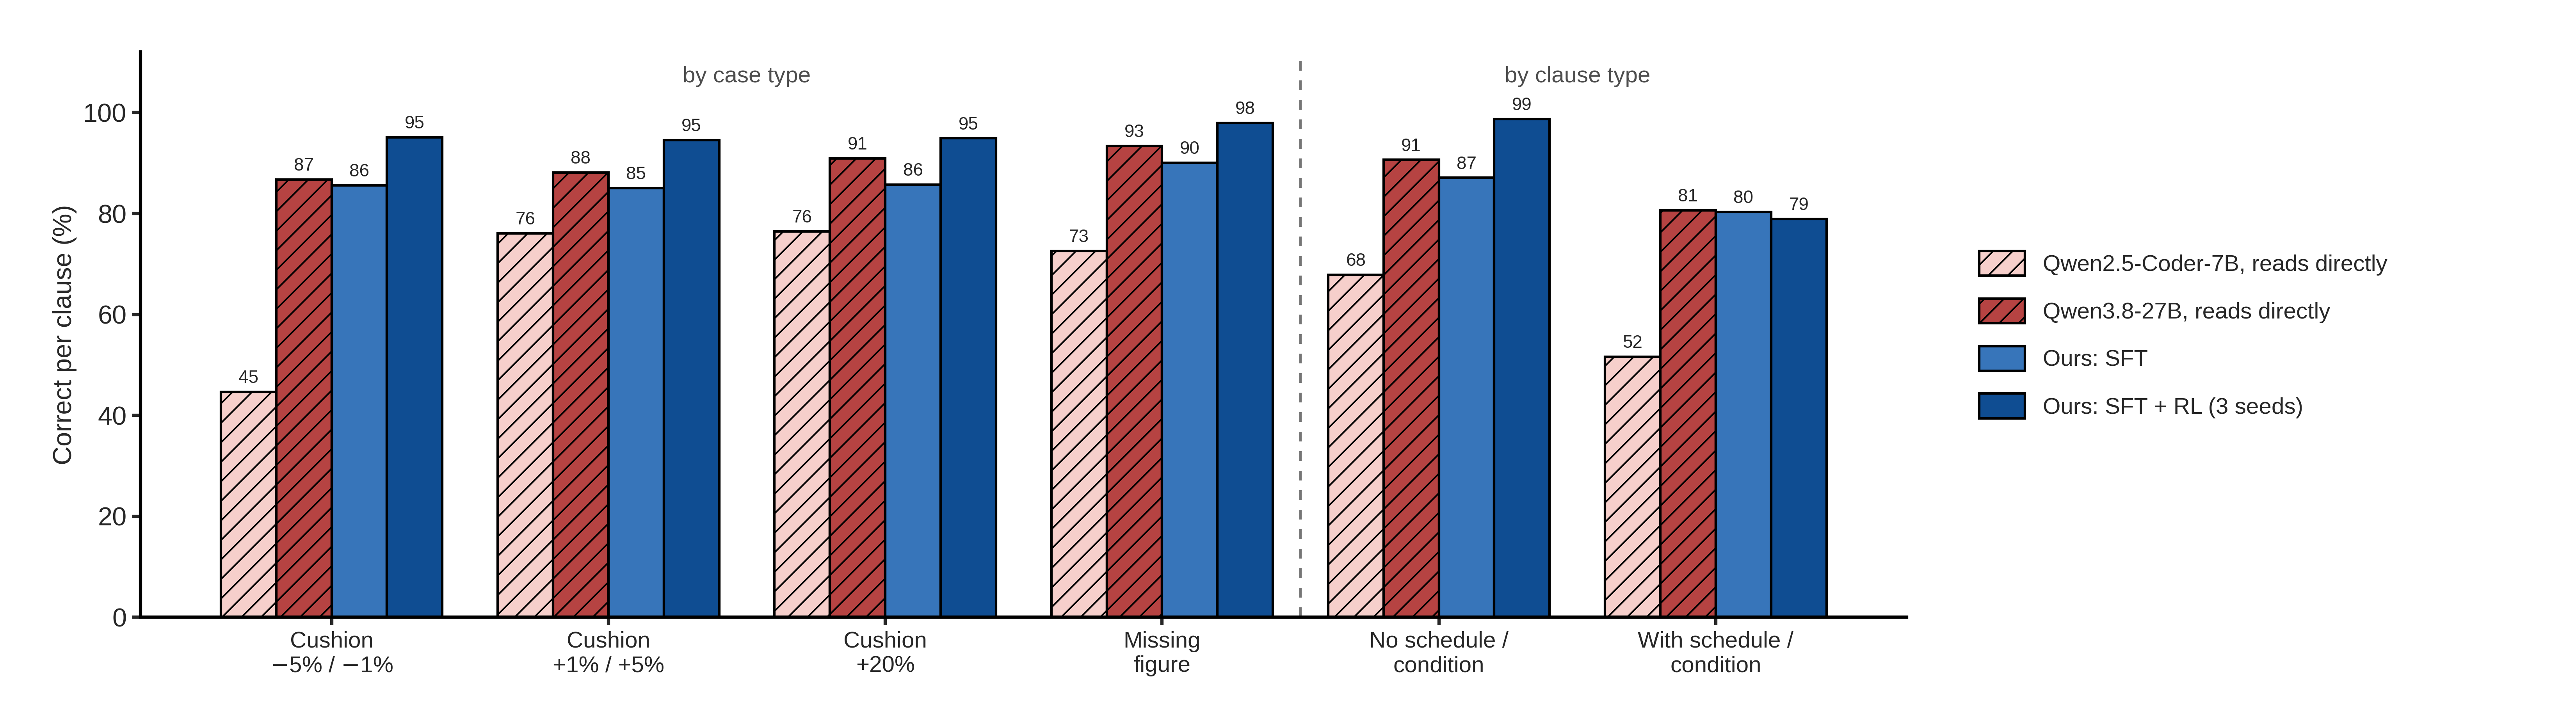

In [13]:
show_fig(paper.fig_cases, 1300)

**Figure 5.** Per-clause score by case type (cushion placed below, near and well above the limit; a needed figure
missing) and by clause type. RL was trained only on clauses without date schedules or conditions: on those it reaches
about 99%, while on the 27 clauses with schedules or conditions it does not improve on SFT.

In [14]:
show_table(paper.table_sensitivity)

| Analysis | Setting: A → B | A | B | Note |
|---|---|---|---|---|
| Answer-token limit (direct readers) | Qwen2.5-Coder-7B: 1,024 → 4,096 tokens | 62.8 | 64.8 | cut off: 54 → 1 |
|  | Qwen2.5-Coder-32B: 1,024 → 4,096 tokens | 76.3 | 85.8 | cut off: 151 → 3 |
|  | Qwen3.8-27B: 1,024 → 4,096 tokens | 30.3 | 88.8 | cut off: 784 → 109 |
| Formula interface (formalizers) | SFT (789 pairs): strict → typed subset | 85.8 | 90.0 |  |
|  | SFT + RL, v1 (no interface term): strict → typed subset | 58.4 | 91.3 |  |
| Clause type | SFT: no schedule/condition → with | 87.1 | 80.3 | n = 116 / 27 |
|  | SFT + RL v2 (3 seeds): no schedule/condition → with | 98.8 ± 0.5 | 78.9 ± 6.6 | n = 116 / 27 |

\begin{table}[t]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{Sensitivity analyses (per-clause score). Direct readers were first run with a 1,024-token answer limit; long-reasoning models were cut off, so the main table uses 4,096. The strict interface rule (the pre-registered one) is used throughout the paper; the lenient rule only diagnoses RL v1. RL v2 was trained only on clauses without date schedules or conditions; its rows are mean $\pm$ s.d. over three seeds.}
\label{tab:sensitivity}
\begin{adjustbox}{max width=\linewidth}
\begin{tabular}{@{}llrrl@{}}
\toprule
\textbf{Analysis} & \textbf{Setting: A $\rightarrow$ B} & \textbf{A} & \textbf{B} & \textbf{Note} \\
\midrule
Answer-token limit (direct readers) & Qwen2.5-Coder-7B: 1,024 $\rightarrow$ 4,096 tokens & 62.8 & 64.8 & cut off: 54 $\rightarrow$ 1 \\
 & Qwen2.5-Coder-32B: 1,024 $\rightarrow$ 4,096 tokens & 76.3 & 85.8 & cut off: 151 $\rightarrow$ 3 \\
 & Qwen3.8-27B: 1,024 $\rightarrow$ 4,096 tokens & 30.3 & 88.8 & cu

## 7. Claims and limits

**Supported.** (1) SFT then RL with a solver-checked, interface-enforcing reward improves a 7B formalizer by about 9
points on held-out borrowers (three seeds). (2) The 7B formalizer answers headroom questions better than 27B and 32B open
models reading directly. (3) Formalizing beats reading at equal size
by about 30 points, mostly on the earnings cushion. (4) 71% of RL formulas are proven correct for every input; two
independent formulas that Z3 proves equivalent are right 98-100% of the time, covering 80-92% of clauses.

**Not claimed.** Real-world compliance accuracy (figures are constructed, references are two
model readings checked by Z3, not expert labels); clauses with date schedules or conditions (RL does not help there yet).
RL v2 is the second RL run, designed after the first one failed; its comparisons were fixed before training.

In [15]:
import os
for d in (paper.FIG, paper.TAB):
    print(d.relative_to(paper.P.ROOT)); [print('   ', f) for f in sorted(os.listdir(d))]

results/paper/figures
    fig0_overview.pdf
    fig0_overview.png
    fig0_overview.tex
    fig1_main.pdf
    fig1_main.png
    fig2_size.pdf
    fig2_size.png
    fig3_training.pdf
    fig3_training.png
    fig4_verification.pdf
    fig4_verification.png
    fig5_cases.pdf
    fig5_cases.png
    fig_method.pdf
    fig_method.png
    fig_method.tex
results/paper/tables
    tab1_benchmark.md
    tab1_benchmark.tex
    tab2_main.md
    tab2_main.tex
    tab3_paired.md
    tab3_paired.tex
    tab4_verification.md
    tab4_verification.tex
    tab5_selfcheck.md
    tab5_selfcheck.tex
    tab6_sensitivity.md
    tab6_sensitivity.tex
